In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

pd.set_option('display.max_columns', None)  # none은 제한값 자리(몇개 열까지 보여줄까)
pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기: 2-5 train_test_comparison에서 제거된 이상치까지 반영된 데이터셋
# ============================================================

train_full = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '0_train_full_clean.parquet')
test = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '0_test_future.parquet')
test_pred = pd.read_csv(PROJECT_ROOT.parent / 'data' / 'result_v1.csv')

from sklearn import set_config
set_config(display='text')
# scikit-learn의 HTML 출력 과정에서 발생한 cp949 간 UTF-8 충돌 때문에 넣는 코드

In [2]:
print(test.shape, test_pred.shape)

(114111, 34) (186263, 2)


In [2]:
# reindex(): 부모 인덱스 기준, 자식을 재정렬하여 가져옴
# 여러 컬럼을 한번에 지정해서 index에 맞게 다 들고 올 수 있음(map이랑 다른부분)
# reindex 용법: 부모[컬럼] = 자식[컬럼].reindex(부모인덱스)
# 부모, 자식 크기가 안맞을때 부모인덱스에 해당하는만큼만 자식에서 가져온다.
# 자식도 같은 인덱스가 지정 돼 있어야 한다.(set_index()를 써서라도)
test['test_pred_v1'] = (
    test_pred
    .set_index('row_id')['pred_maxrise_6h']  # 인덱스로 설정해야 매칭 가능
    # set_index로 인덱스 설정 -> pred_maxrise_6h 불러오기
    .reindex(test.index)
)

# 원본 예측값에 결측치가 없는지 확인
assert not test_pred['pred_maxrise_6h'].isnull().any(), '원본 예측값에 결측치 있음'

# reindex 후 미매칭 여부 확인
assert not test['test_pred_v1'].isnull().any(), '인덱스 미매칭 발생'


# map(): 시리즈나 딕셔너리, 함수로 매핑규칙을 지정, 부모와 자식의 인덱스가 같기만 하면
# 시리즈만 받으므로 여러 열을 가져오지 못한다.
# 매핑규칙으로 부모와 같은 인덱스와 값을 가진 자녀 객체가 있으면 됨

# map 용법: 부모[컬럼] = 부모 인덱스.map(매핑규칙(자녀의 것으로서))  # 부모 인덱스를 매핑규칙에 따라 자식 인덱스와 매칭
# 자식과 부모의 인덱스가 같은 것만 매핑 가능(set_index()를 써서라도)
# test['test_pred_v1'] = (
# test.index  # test는 'row_id'가 이미 인덱스라서 이렇게 들고옴
# .map(test_pred.set_index('row_id')['pred_maxrise_6h']) 
# )

In [4]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

target_col = 'target_maxrise_6h'  # 모델링 학습부터는 반드시 빼내야 함

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = wl_cols + rain_cols + env_cols
num_cols_fe_wl = num_cols + [
    col for col in wl_diff_cols if col != 'wl_t'
]
num_cols_fe = num_cols_fe_wl + [
    col for col in rain_int_cols if col not in ['imerg_rain_1h', 'sfc_rain_1h']
]

print(f"""<변수개수 검증>
    수위변수: {len(wl_cols)}
    강우변수: {len(rain_cols)}, 
    환경변수: {len(env_cols)}, 
    수위차분(wl_t포함): {len(wl_diff_cols)},
    강우강도(rain_1h포함): {len(rain_int_cols)}
    기존 숫자열(수위 + 강우 + 환경): {len(num_cols)}, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): {len(num_cols_fe_wl)},
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): {len(num_cols_fe)}
""")

<변수개수 검증>
    수위변수: 6
    강우변수: 9, 
    환경변수: 7, 
    수위차분(wl_t포함): 6,
    강우강도(rain_1h포함): 6
    기존 숫자열(수위 + 강우 + 환경): 22, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): 27,
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): 31



In [5]:
# 최종 예측셋의 데이터별 잔차, SSE의 내림차순 정렬
# 잔차 (실제값 - 예측값)
test['residual'] = test['target_maxrise_6h'] - test['test_pred_v1']

# 잔차제곱 (각 행의 SSE 기여값)
test['residual_sq'] = test['residual'] ** 2

# 잔차 절대값 기준 내림차순 정렬
display(
    test.sort_values('residual', key=abs, ascending=False)[['station_id'] + rain_cols + [target_col] + ['test_pred_v1']].head(100)
)

# # 잔차제곱 기준 내림차순 정렬
# display(
#     test.sort_values('residual_sq', ascending=False)
# )

# 전체 SSE
print(f"SSE: {test['residual_sq'].sum():.6f}")

,station_id,imerg_rain_1h,imerg_rain_6h,imerg_rain_24h,sfc_rain_1h,sfc_rain_6h,sfc_rain_24h,radar_reflectivity_mean,radar_reflectivity_p95,radar_reflectivity_ge20_fraction,target_maxrise_6h,test_pred_v1
row_id,,,,,,,,,,,,
TE_000150989,ST0302,0.555,0.555,0.555,0.0,0.0,0.0,16.185,24.210,0.2471,3.42,0.033037
TE_000039994,ST0433,20.660,39.377,39.377,1.5,1.5,1.5,28.177,32.109,0.9824,3.16,0.078539
TE_000020895,ST0302,0.890,1.445,1.445,19.5,19.5,19.5,40.431,53.038,0.9258,3.43,0.370515
TE_000081035,ST0093,0.795,1.330,1.330,0.0,0.0,0.0,17.745,27.499,0.3789,3.11,0.057508
TE_000055832,ST0207,1.200,2.286,2.286,0.0,0.0,0.0,21.556,30.792,0.6992,3.14,0.095647
TE_000122659,ST0093,1.320,2.650,2.650,0.0,0.0,0.0,23.023,26.270,0.9189,3.10,0.061631
TE_000162662,ST0433,21.346,60.722,60.722,11.5,13.0,13.0,32.783,40.570,1.0000,3.27,0.234186
TE_000016542,ST0093,3.292,8.437,8.570,0.0,0.0,0.0,21.880,26.170,0.7637,3.10,0.088720
TE_000039179,ST0433,4.158,64.880,64.880,14.5,27.5,27.5,30.367,35.292,1.0000,3.27,0.261669


SSE: 4670.495803


In [6]:
# 6시간 강우량 차이
test['rain_diff_6h'] = (
    test['imerg_rain_6h'] - test['sfc_rain_6h']
)

# 절대 차이
test['rain_diff_abs_6h'] = test['rain_diff_6h'].abs()

# 관측소별 집계
station_rain_diff = (
    test.groupby('station_id')
    .agg(
        count=('rain_diff_abs_6h', 'size'),
        mean_diff=('rain_diff_abs_6h', 'mean'),
        median_diff=('rain_diff_abs_6h', 'median'),
        p90_diff=('rain_diff_abs_6h', lambda x: x.quantile(0.9)),
        max_diff=('rain_diff_abs_6h', 'max'),
        rmse=('residual_sq', lambda x: (x.mean()) ** 0.5),
        sse=('residual_sq', 'sum')
    )
    .sort_values('mean_diff', ascending=False)
)

display(station_rain_diff)

,count,mean_diff,median_diff,p90_diff,max_diff,rmse,sse
station_id,,,,,,,
ST0221,256,11.278199,3.8990,31.8660,77.738,0.409079,42.840527
ST0371,191,10.894236,2.7930,20.8840,167.815,0.176632,5.958989
ST0353,256,10.666719,4.0850,31.6710,77.683,0.272016,18.942068
ST0393,256,10.666719,4.0850,31.6710,77.683,0.304907,23.799875
ST0029,256,10.622223,2.2620,28.1330,102.569,0.122338,3.831477
ST0404,256,10.609258,2.0805,34.7020,92.434,0.191545,9.392482
ST0173,256,10.609258,2.0805,34.7020,92.434,0.162594,6.767830
ST0419,256,9.593617,2.2325,29.7600,66.972,0.244374,15.287927
ST0007,241,9.420394,3.8080,24.4380,86.490,0.219104,11.569602


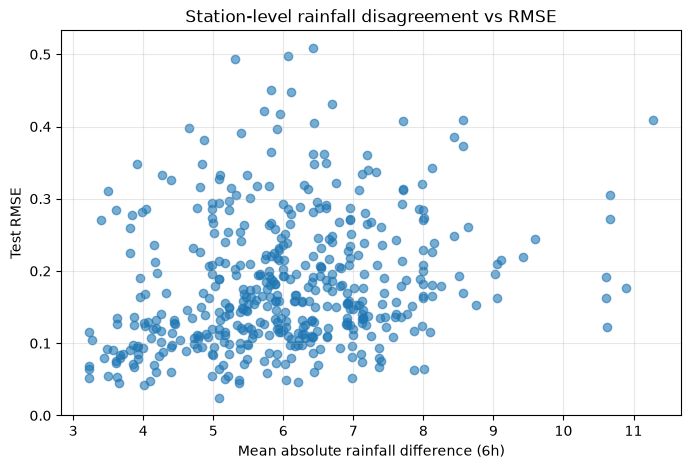

Pearson correlation: 0.2356542609974692


In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    station_rain_diff['mean_diff'],
    station_rain_diff['rmse'],
    alpha=0.6
)

plt.xlabel('Mean absolute rainfall difference (6h)')
plt.ylabel('Test RMSE')
plt.title('Station-level rainfall disagreement vs RMSE')
plt.grid(alpha=0.3)
plt.show()

print(
    'Pearson correlation:',
    station_rain_diff['mean_diff'].corr(station_rain_diff['rmse'])
)

In [8]:
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

# 1. 강우 차이 변수 생성 (6h는 기존 변수 재사용)
for h in [1, 24]:
    test[f'rain_diff_{h}h'] = (
        test[f'imerg_rain_{h}h'] - test[f'sfc_rain_{h}h']
    )

# 2. 잔차 생성
test['residual'] = (
    test['target_maxrise_6h'] - test['test_pred_v1']
)

# 3. 잔차 모델 입력 변수
features = [
    'imerg_rain_1h', 'imerg_rain_6h', 'imerg_rain_24h',
    'sfc_rain_1h', 'sfc_rain_6h', 'sfc_rain_24h',
    'rain_diff_1h', 'rain_diff_6h', 'rain_diff_24h',
    'test_pred_v1'
]

# 4. Hold-out 분리
tr_idx, va_idx = train_test_split(
    np.arange(len(test)),
    test_size=0.2,
    random_state=42
)

X_tr = test.iloc[tr_idx][features]
X_va = test.iloc[va_idx][features]

y_tr = test.iloc[tr_idx]['residual']
y_va = test.iloc[va_idx]['residual']

# 5. 잔차 보정 모델
resid_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    min_child_samples=100,
    reg_lambda=10,
    verbosity=-1,
    random_state=42
)

resid_model.fit(
    X_tr, y_tr,
    eval_set=[(X_va, y_va)],
    callbacks=[
        lgb.early_stopping(50, verbose=False)
    ]
)

# 6. 잔차 예측 및 기존 예측값 보정
resid_pred = resid_model.predict(X_va)

base_pred = test.iloc[va_idx]['test_pred_v1'].to_numpy()
true_y = test.iloc[va_idx]['target_maxrise_6h'].to_numpy()

corrected_pred = base_pred + resid_pred

# 7. RMSE 비교
rmse_before = root_mean_squared_error(true_y, base_pred)
rmse_after = root_mean_squared_error(true_y, corrected_pred)

print(f'보정 전 RMSE: {rmse_before:.6f}')
print(f'보정 후 RMSE: {rmse_after:.6f}')
print(f'개선량: {rmse_before - rmse_after:+.6f}')
print(f'개선율: {(rmse_before - rmse_after) / rmse_before * 100:+.2f}%')

c:\Users\20162180\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


보정 전 RMSE: 0.201081
보정 후 RMSE: 0.193389
개선량: +0.007692
개선율: +3.83%


In [9]:
# A모델: 강우 차이 변수 제외
features_A = [
    'imerg_rain_1h', 'imerg_rain_6h', 'imerg_rain_24h',
    'sfc_rain_1h', 'sfc_rain_6h', 'sfc_rain_24h',
    'test_pred_v1'
]

# 기존 Hold-out 그대로 사용
X_tr_A = test.iloc[tr_idx][features_A]
X_va_A = test.iloc[va_idx][features_A]

# 기존 B모델과 동일한 하이퍼파라미터
resid_model_A = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    min_child_samples=100,
    reg_lambda=10,
    verbosity=-1,
    random_state=42
)

resid_model_A.fit(
    X_tr_A, y_tr,
    eval_X=X_va_A,
    eval_y=y_va,
    callbacks=[
        lgb.early_stopping(50, verbose=False)
    ]
)

# A모델 잔차 보정
resid_pred_A = resid_model_A.predict(X_va_A)
corrected_pred_A = base_pred + resid_pred_A

# RMSE 비교
rmse_A = root_mean_squared_error(true_y, corrected_pred_A)

print(f'기존 모델 RMSE: {rmse_before:.6f}')
print(f'A모델 (강우 차이 제외): {rmse_A:.6f}')
print(f'B모델 (강우 차이 포함): {rmse_after:.6f}')
print(f'강우 차이 변수 추가 효과: {rmse_A - rmse_after:+.6f}')

기존 모델 RMSE: 0.201081
A모델 (강우 차이 제외): 0.193775
B모델 (강우 차이 포함): 0.193389
강우 차이 변수 추가 효과: +0.000386
